# Módulo 10 — Visualização de Dados | E-commerce

**Objetivo:** explorar os produtos do e-commerce e comunicar padrões relevantes por meio de sete visualizações.

> **Observação sobre o arquivo:** o enunciado menciona `ecommerce_estatistica.csv`, mas o arquivo disponibilizado nesta atividade chama-se `ecommerce_preparados.csv`. O notebook utiliza o arquivo recebido. Deixe o CSV na mesma pasta deste notebook antes de executar as células.

## 1. Carregamento e preparação dos dados

O conjunto possui 2.199 produtos e 24 colunas. Para os gráficos, foram selecionadas variáveis com interpretação direta: preço, nota, quantidade de avaliações, marca e gênero. As colunas de texto de avaliações e os campos codificados não são necessários para estas visualizações.

Há valores ausentes em algumas variáveis — por exemplo, nota, avaliações, desconto e material. Cada gráfico utiliza `dropna()` ou contagens explícitas para trabalhar com os registros disponíveis, sem preencher valores ausentes artificialmente.


In [1]:
# Bibliotecas utilizadas
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual dos gráficos
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)

# Leitura do arquivo CSV disponibilizado
df = pd.read_csv("ecommerce_preparados.csv")

# Remoção da coluna de índice salva no CSV, caso exista
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

# Conversão de colunas numéricas, garantindo o tipo adequado
for coluna in ["Nota", "N_Avaliações", "Desconto", "Preço"]:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

print(f"Dimensões da base: {df.shape[0]} linhas e {df.shape[1]} colunas")
display(df.head())


Dimensões da base: 2199 linhas e 23 colunas


,Título,Nota,N_Avaliações,Desconto,Marca,Material,Gênero,Temporada,Review1,Review2,Review3,Qtd_Vendidos,Preço,Nota_MinMax,N_Avaliações_MinMax,Desconto_MinMax,Preço_MinMax,Marca_Cod,Material_Cod,Temporada_Cod,Qtd_Vendidos_Cod,Marca_Freq,Material_Freq
0,Pijama Cirurgico Scrub Roupa Privativa Hospit...,4.0,273.0,NaN,toronto uniformes profissionais,poliéster,Sem gênero,não definido,"Preço justo , bem feito acabamento ok. Única s...","Tamanho bom, costuras de qualidade, porém teci...","Muito bom, só poderia ter os cortes na lateral...",+1000,69.90,0.629630,0.029969,NaN,0.100645,781,122,1,1000.0,0.002274,0.117326
1,Kit 10 Cuecas Boxer Lupo Cueca Box Algodão Mas...,4.5,3034.0,18.0,lupo,algodão,Masculino,outono/inverno,As cuecas são boas; porém você percebe na cost...,"Pelo preço promocional, com ctz tem algum defe...","Serviram muito bem, porém é nítido que o pano ...",+10mil,232.89,0.814815,0.334178,0.213115,0.378585,463,25,3,10000.0,0.042292,0.176444
2,Kit Com 10 Cuecas Boxer Algodão Sem Costura Zo...,4.7,5682.0,20.0,zorba,algodão,Masculino,não definido,O tecido é bom e são confortáveis. Só que a nu...,Vendo comentários de outros consumidores vejo ...,"Produto não é nem de longe original, tecido gr...",+50mil,199.90,0.888889,0.625937,0.245902,0.322329,838,25,1,50000.0,0.009095,0.176444
3,Kit 10 Cuecas Boxer Mash Algodão Cotton Box Or...,4.6,1700.0,22.0,mash,algodão,Masculino,primavera/verão,"As cuecas são boas, porém meu marido usa g e p...","E o tamanho certo, mas em baixo dela, fica mui...",Produto não parece.\nOriginal e veio 2 modelos...,+10mil,229.39,0.851852,0.187197,0.278689,0.372617,494,25,7,10000.0,0.010914,0.176444
4,Kit 3 Short Jeans Feminino Cintura Alta Barato...,4.4,507.0,9.0,menina linda,jean,Feminino,primavera/verão,Estou encantada com essas peças!.\nOs shorts s...,"Recomendo, tecido confortável, igual a foto.","Gostei muito dos shorts, material bom, para us...",+1000,129.20,0.777778,0.055751,0.065574,0.201767,509,74,7,1000.0,0.010005,0.025466


## 2. Análise exploratória inicial

Antes de construir os gráficos, vamos observar tipos de dados, valores ausentes e estatísticas descritivas. Isso ajuda a escolher variáveis e evita interpretar campos sem informação suficiente.


In [2]:
# Tipos de dados e quantidade de valores ausentes
display(df.info())
display(df.isna().sum().sort_values(ascending=False).to_frame("Valores ausentes"))

# Estatísticas descritivas das principais variáveis numéricas
display(df[["Nota", "N_Avaliações", "Desconto", "Preço"]].describe().round(2))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2199 entries, 0 to 2198
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Título               2199 non-null   object 
 1   Nota                 1559 non-null   float64
 2   N_Avaliações         1559 non-null   float64
 3   Desconto             874 non-null    float64
 4   Marca                2199 non-null   object 
 5   Material             1332 non-null   object 
 6   Gênero               2120 non-null   object 
 7   Temporada            2199 non-null   object 
 8   Review1              1515 non-null   object 
 9   Review2              1354 non-null   object 
 10  Review3              1233 non-null   object 
 11  Qtd_Vendidos         2199 non-null   object 
 12  Preço                1964 non-null   float64
 13  Nota_MinMax          1559 non-null   float64
 14  N_Avaliações_MinMax  1559 non-null   float64
 15  Desconto_MinMax      874 non-null    f

None

,Valores ausentes
Desconto,1325
Desconto_MinMax,1325
Review3,966
Material,867
Material_Freq,867
Review2,845
Review1,684
Nota,640
N_Avaliações_MinMax,640
Nota_MinMax,640


,Nota,N_Avaliações,Desconto,Preço
count,1559.00,1559.00,874.00,1964.00
mean,4.56,204.06,15.46,102.71
std,0.36,578.46,10.93,69.98
min,2.30,1.00,5.00,10.88
25%,4.40,8.00,8.00,50.19
50%,4.60,27.00,11.00,78.97
75%,4.80,119.50,20.00,139.15
max,5.00,9077.00,66.00,597.30


### Principais pontos observados

- A base contém **2.199 produtos**.
- A nota média dos produtos com avaliação disponível é de aproximadamente **4,56**, indicando avaliações geralmente altas.
- O preço médio é de aproximadamente **R$ 102,71**, mas há grande variação entre os produtos.
- A quantidade de avaliações apresenta dispersão elevada: alguns produtos concentram muito mais avaliações do que a maioria.
- Existem valores ausentes em diversas colunas. Por isso, cada visualização considera apenas os registros válidos para as variáveis utilizadas.

Os números acima são descritivos da base recebida e não representam, por si só, vendas efetivamente realizadas ou causalidade.


## 3. Histograma — distribuição dos preços

O histograma permite observar em quais faixas de preço há maior concentração de produtos. Valores ausentes são removidos apenas desta visualização.


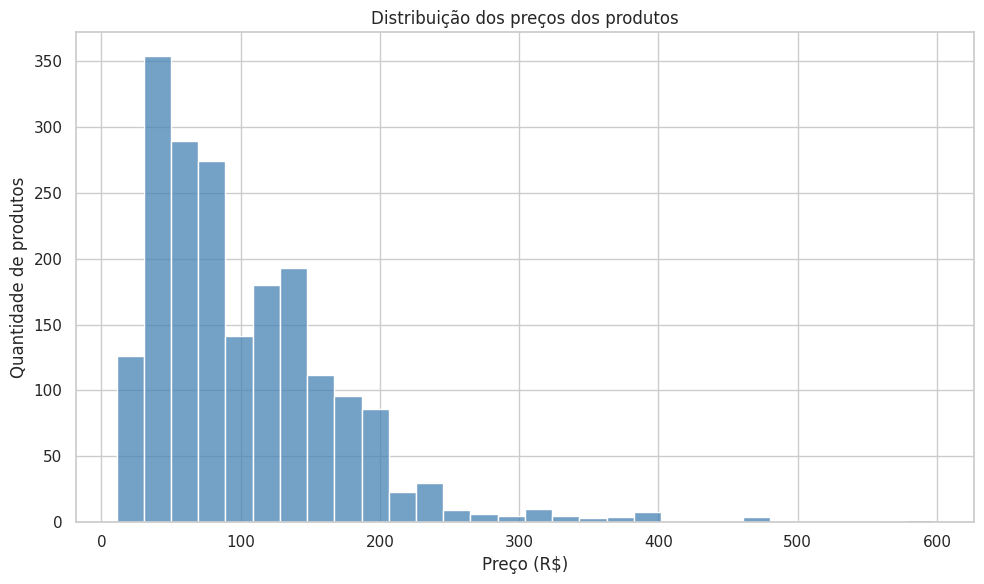

In [3]:
# Histograma da variável Preço
precos = df["Preço"].dropna()

plt.figure(figsize=(10, 6))
sns.histplot(precos, bins=30, kde=False, color="steelblue")
plt.title("Distribuição dos preços dos produtos")
plt.xlabel("Preço (R$)")
plt.ylabel("Quantidade de produtos")
plt.tight_layout()
plt.show()


## 4. Gráfico de dispersão — preço e nota

O gráfico de dispersão permite verificar visualmente se existe algum padrão entre o preço e a nota atribuída aos produtos. Cada ponto representa um produto com as duas informações disponíveis.


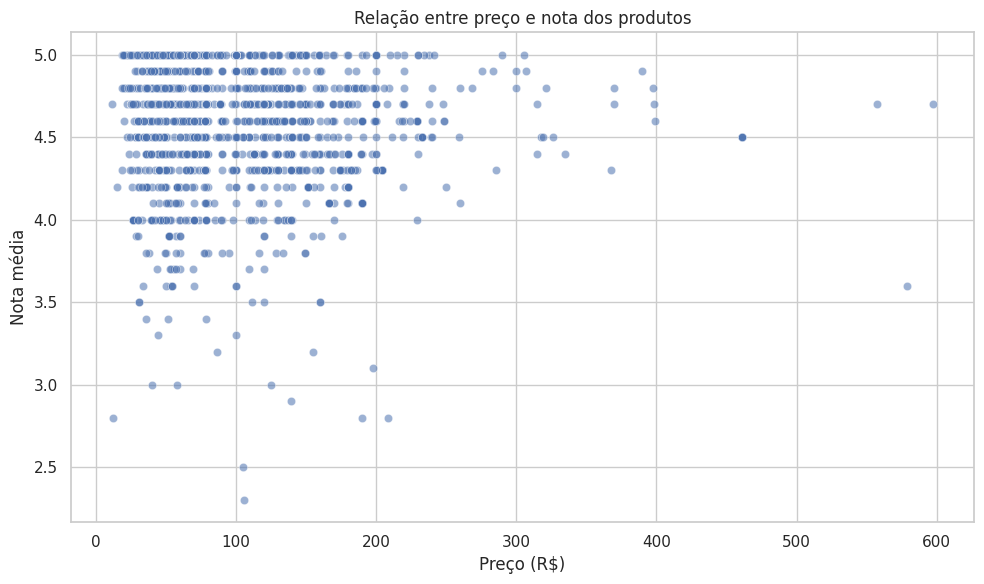

In [4]:
# Relação entre preço e nota dos produtos
dados_dispersao = df[["Preço", "Nota"]].dropna()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=dados_dispersao, x="Preço", y="Nota", alpha=0.55)
plt.title("Relação entre preço e nota dos produtos")
plt.xlabel("Preço (R$)")
plt.ylabel("Nota média")
plt.tight_layout()
plt.show()


## 5. Mapa de calor — correlação entre variáveis numéricas

A correlação mede a intensidade e a direção da associação linear entre duas variáveis numéricas. Valores próximos de 1 indicam associação positiva; próximos de -1, associação negativa; e próximos de 0, associação linear fraca. Correlação não significa causalidade.


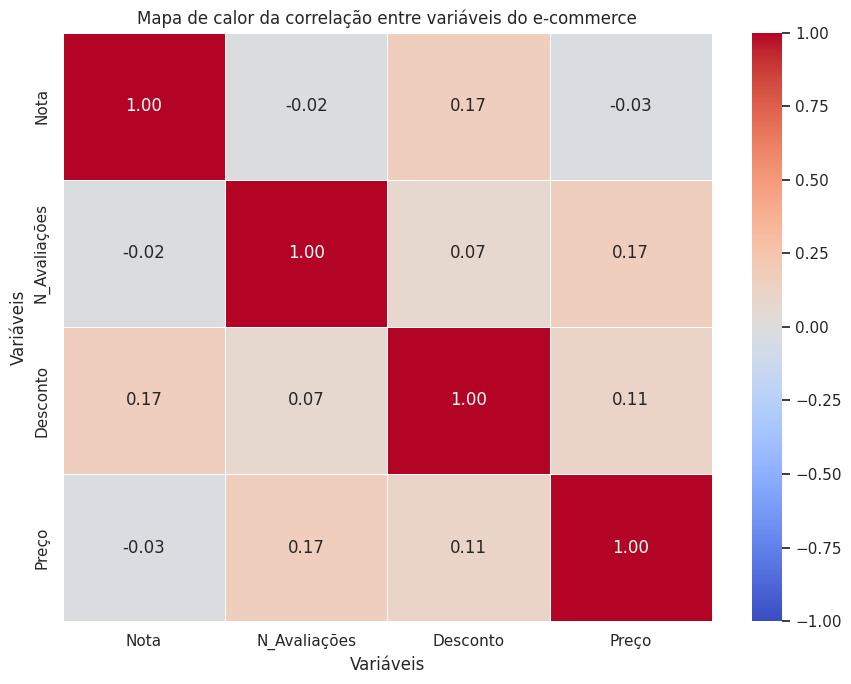

In [5]:
# Seleção de variáveis numéricas originais para a matriz de correlação
variaveis_corr = df[["Nota", "N_Avaliações", "Desconto", "Preço"]]
matriz_corr = variaveis_corr.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(matriz_corr, annot=True, cmap="coolwarm", fmt=".2f",
            vmin=-1, vmax=1, linewidths=0.5)
plt.title("Mapa de calor da correlação entre variáveis do e-commerce")
plt.xlabel("Variáveis")
plt.ylabel("Variáveis")
plt.tight_layout()
plt.show()


## 6. Gráfico de barras — marcas com mais produtos

O gráfico de barras compara a quantidade de registros por marca. São exibidas as dez marcas mais frequentes na base para facilitar a leitura.


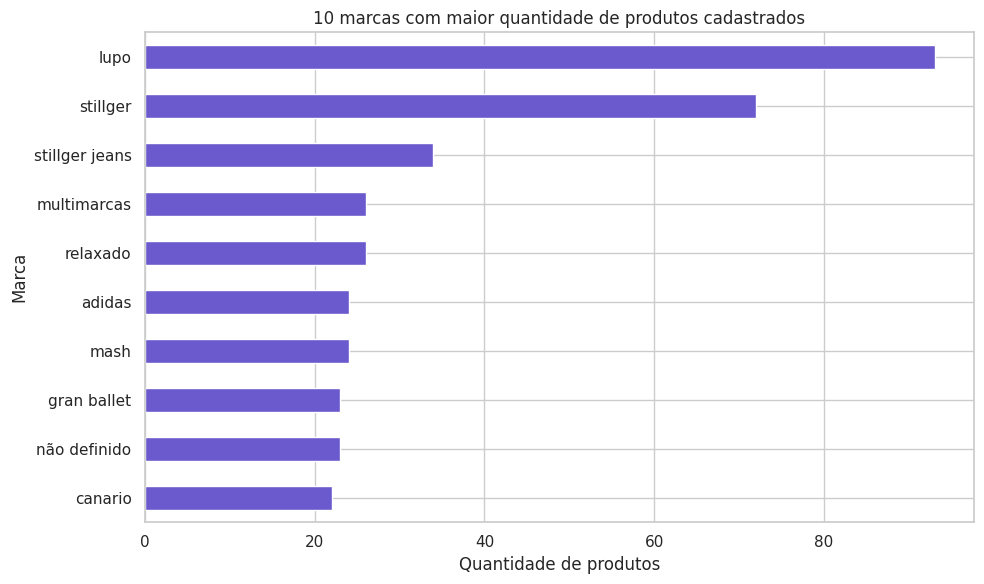

In [6]:
# Contagem dos produtos por marca: dez marcas com mais registros
top_marcas = df["Marca"].fillna("Não informado").value_counts().head(10).sort_values()

plt.figure(figsize=(10, 6))
top_marcas.plot(kind="barh", color="slateblue")
plt.title("10 marcas com maior quantidade de produtos cadastrados")
plt.xlabel("Quantidade de produtos")
plt.ylabel("Marca")
plt.tight_layout()
plt.show()


## 7. Gráfico de pizza — distribuição por gênero

O gráfico de pizza mostra a participação de cada categoria de gênero nos produtos cadastrados. Para manter a visualização legível, as categorias menos frequentes são agrupadas em “Outros”; valores ausentes são identificados como “Não informado”.


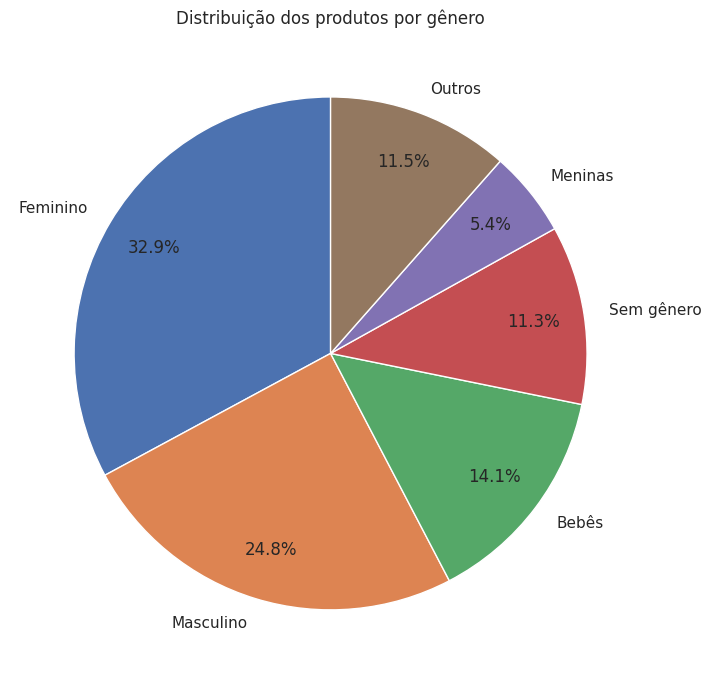

In [7]:
# Preparação das categorias de gênero
generos = df["Gênero"].fillna("Não informado").value_counts()
principais = generos.head(5)
outros = generos.iloc[5:].sum()

if outros > 0:
    principais.loc["Outros"] = outros

plt.figure(figsize=(9, 7))
plt.pie(principais.values, labels=principais.index, autopct="%1.1f%%",
        startangle=90, pctdistance=0.8)
plt.title("Distribuição dos produtos por gênero")
plt.ylabel("")
plt.tight_layout()
plt.show()


## 8. Gráfico de densidade — distribuição dos preços

A curva de densidade (KDE) é uma estimativa suavizada da distribuição dos preços. Ela complementa o histograma, ajudando a identificar regiões de maior concentração.


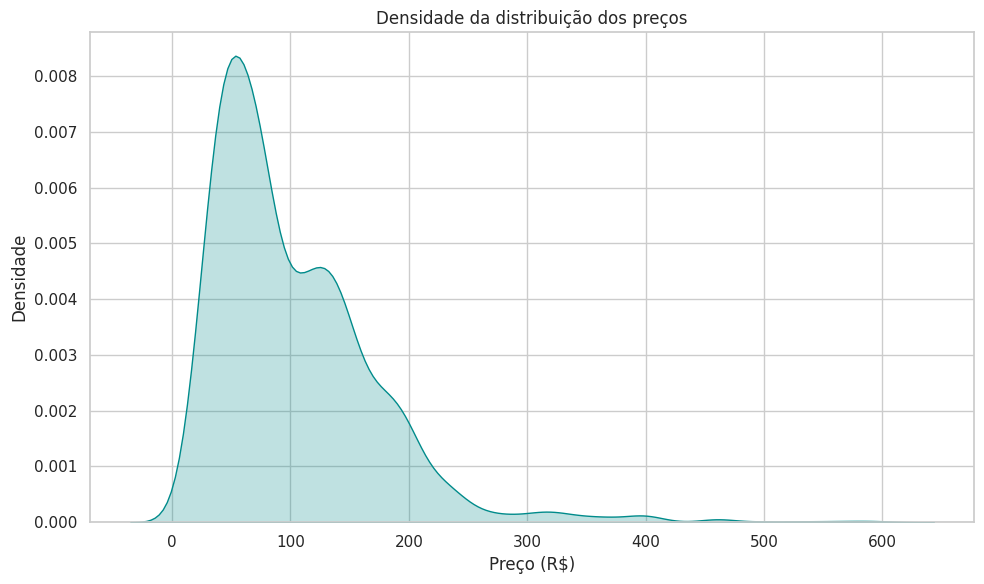

In [8]:
# Curva de densidade dos preços
precos = df["Preço"].dropna()

plt.figure(figsize=(10, 6))
sns.kdeplot(x=precos, fill=True, color="darkcyan")
plt.title("Densidade da distribuição dos preços")
plt.xlabel("Preço (R$)")
plt.ylabel("Densidade")
plt.tight_layout()
plt.show()


## 9. Gráfico de regressão — preço e nota

A regressão linear adiciona uma linha de tendência à relação entre preço e nota. Ela ajuda a visualizar se há uma tendência linear, mas não demonstra que o preço cause uma nota maior ou menor.


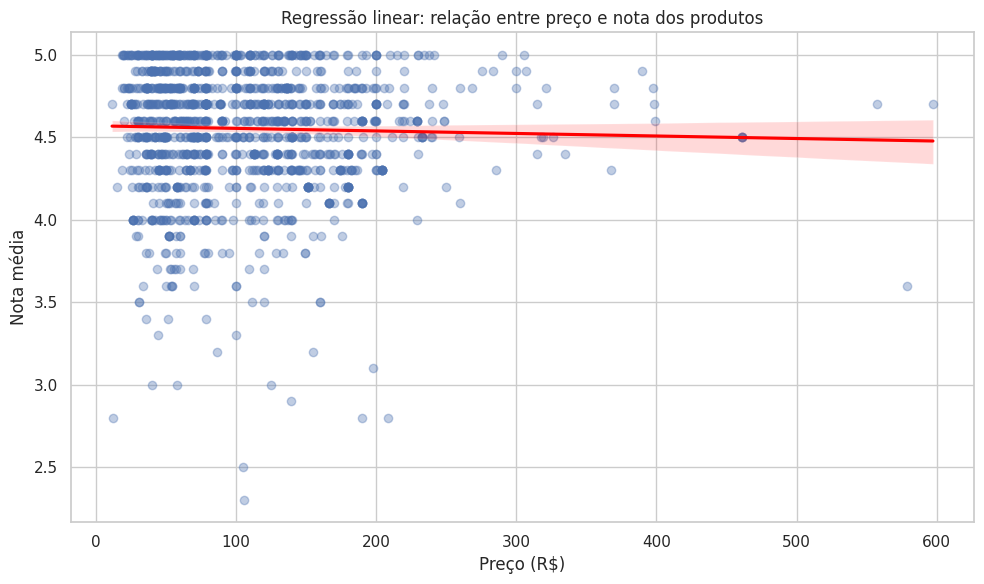

In [9]:
# Regressão linear entre preço e nota
dados_regressao = df[["Preço", "Nota"]].dropna()

plt.figure(figsize=(10, 6))
sns.regplot(data=dados_regressao, x="Preço", y="Nota",
            scatter_kws={"alpha": 0.35}, line_kws={"color": "red"})
plt.title("Regressão linear: relação entre preço e nota dos produtos")
plt.xlabel("Preço (R$)")
plt.ylabel("Nota média")
plt.tight_layout()
plt.show()


## 10. Conclusão

As visualizações permitem analisar diferentes aspectos do catálogo: a distribuição dos preços, a relação entre preço e nota, a correlação entre variáveis numéricas, as marcas mais presentes e a composição dos produtos por gênero.

A base apresenta notas médias elevadas entre os produtos avaliados e uma variação considerável de preços e de quantidade de avaliações. Para uma análise de negócio mais aprofundada, seria interessante investigar produtos com muitas avaliações, comparar notas por marca e estudar a relação entre descontos e desempenho — sempre considerando os valores ausentes e os limites dos dados disponíveis.

**Entrega:** salve este notebook (`.ipynb`) e mantenha o arquivo `ecommerce_preparados.csv` na mesma pasta para que o código possa ser executado.
